# 1. Introducción teórica

## 1.1. Filtrado digital de señales

Los filtros digitales se pueden clasificar principalmente en dos categorías: filtros de respuesta al impulso finita (FIR) y filtros de respuesta al impulso infinita (IIR).

## 1.2. Filtros FIR (Finite Impulse Response)

Los filtros FIR se caracterizan por tener una respuesta al impulso de duración finita. Su salida depende exclusivamente de un número finito de muestras presentes y pasadas de la entrada.

Su ecuación en diferencias es:

$$
y[n]=\sum_{k=0}^{M}b_kx[n-k]
$$

Donde $x[n]$ representa la señal de entrada, $y[n]$ la señal de salida y $b_k$ los coeficientes del filtro.

Su función de transferencia puede expresarse como:

$$
H(z)=\sum_{k=0}^{M}b_kz^{-k}
$$

Los filtros FIR  no poseen realimentación, por lo que su estabilidad está garantizada para coeficientes finitos.

Además, Estos filtros pueden ser diseñados para tener fase lineal . Esto significa que todas las componentes frecuenciales sufren el mismo retardo temporal, evitando la distorsión de fase.

Como desventaja, generalmente requieren un orden mayor que los filtros IIR para conseguir especificaciones de atenuación y transición equivalentes, lo que puede incrementar el costo computacional.

## 1.3. Filtros IIR (Infinite Impulse Response)

Los filtros IIR a diferencia de los FIR, utilizan realimentación: su salida depende tanto de muestras presentes y pasadas de la entrada como de muestras anteriores de la propia salida.

Su ecuación en diferencias general es:

$$
y[n]=\sum_{k=0}^{M}b_kx[n-k]
-\sum_{k=1}^{N}a_ky[n-k]
$$

Su función de transferencia está dada por:

$$
H(z)=
\frac{\sum_{k=0}^{M}b_kz^{-k}}
{1+\sum_{k=1}^{N}a_kz^{-k}}
$$

La presencia de realimentación permite obtener respuestas frecuenciales selectivas con órdenes relativamente bajos. Por este motivo, los filtros IIR suelen presentar un menor costo computacional que los FIR para determinadas especificaciones de filtrado.

Su estabilidad depende de la ubicación de sus polos en el plano. Para que un filtro IIR causal sea estable, todos sus polos deben encontrarse estrictamente dentro del círculo unitario en el plano Z.

Una de sus principales desventajas es que generalmente presentan una respuesta de fase no lineal, lo que puede producir distorsiones temporales en señales.

## 1.4. Diseño de filtros IIR

Para diseñar un filtro digital es necesario establecer previamente una plantilla de especificaciones frecuenciales. Esta define las condiciones que debe cumplir la respuesta en magnitud del filtro:

- Frecuencia de borde de banda pasante ($w_p$): determina hasta dónde se desea conservar la señal.
- Frecuencia de borde de banda de rechazo ($w_s$): establece a partir de qué frecuencia se exige una atenuación determinada.
- Atenuación máxima en banda pasante ($G_{pass}$): determina la máxima variación permitida en la banda de paso.
- Atenuación mínima en banda de rechazo ($G_{stop}$): determina la atenuación mínima exigida para las componentes no deseadas.

La atenuación en decibeles se define como:

$$
A(f)=-20\log_{10}|H(f)|
$$

Por lo tanto, una mayor atenuación implica una menor amplitud de las componentes frecuenciales a la salida.

La función `iirdesign` de la biblioteca SciPy permite diseñar filtros IIR a partir de estas especificaciones, calculando el orden y los coeficientes necesarios para satisfacer la plantilla establecida.

En la práctica, no es posible implementar un filtro ideal, ya que requeriría una transición instantánea entre la banda pasante y la banda de rechazo, lo que implica una respuesta al impulso de duración infinita. Por este motivo, se utilizan distintas aproximaciones matemáticas que permiten obtener filtros realizables y cuyas respuestas en magnitud se aproximan a las especificaciones deseadas.

Entre las aproximaciones utilizadas se encuentran Butterworth, Chebyshev  I, Chebyshev  II y elíptica (Cauer). Cada una presenta diferentes características en cuanto a la planicidad de la banda pasante, el ripple permitido, la atenuación en la banda de rechazo y la selectividad frecuencial. 

Estas aproximaciones permiten controlar  la respuesta en magnitud. Por lo tanto, aunque el filtro cumpla las especificaciones de amplitud, puede introducir distorsiones de fase que modifiquen la forma temporal de la señal.

## 1.5. Representación mediante secciones de segundo orden (SOS)

La función de transferencia de un filtro IIR de orden elevado puede representarse como una única función racional con  polos y ceros. Sin embargo, implementar directamente sus coeficientes puede generar problemas de precisión numérica y errores de redondeo. Esto se debe, en parte, a la presencia de realimentación, los errores numéricos introducidos durante los cálculos pueden propagarse a través de las sucesivas iteraciones del sistema. Pequeñas variaciones en los coeficientes pueden modificar la ubicación de los polos y, por lo tanto, alterar significativamente la respuesta del filtro e incluso comprometer su estabilidad.

Para reducir estos problemas se utiliza una representación en cascada de secciones de segundo orden (SOS, Second-Order Sections).

En esta representación, la función de transferencia total se expresa como el producto de funciones de segundo orden:

$$
H(z)=\prod_{i=1}^{K}H_i(z)
$$

Cada sección tiene la forma:

$$
H_i(z)=
\frac{b_{0,i}+b_{1,i}z^{-1}+b_{2,i}z^{-2}}
{a_{0,i}+a_{1,i}z^{-1}+a_{2,i}z^{-2}}
$$

La representación SOS mejora la robustez numérica durante la implementación, especialmente en filtros de orden elevado, al reducir los problemas asociados a la representación directa de polinomios de alto grado.

En SciPy, el parámetro `output='sos'` permite obtener directamente esta representación.


## 1.6. Filtrado bidireccional: función `filtfilt`

El filtrado convencional de un sistema causal introduce la respuesta de fase propia del filtro. Para aplicaciones en las que se dispone de la señal completa y no se requiere procesamiento en tiempo real, puede utilizarse un filtrado bidireccional.

La función `filtfilt` realiza dos pasadas sobre la señal

Conceptualmente, la respuesta total en frecuencia resulta:

$$
H_{total}(e^{j\omega})=
H(e^{j\omega})H(e^{-j\omega})
$$

Para filtros con coeficientes reales:

$$
H_{total}(e^{j\omega})=|H(e^{j\omega})|^2
$$

La fase se cancela y se obtiene una respuesta de fase nula, evitando el desplazamiento temporal de las componentes frecuenciales en la región interior de la señal.

Sin embargo, como consecuencia de aplicar el filtro dos veces, el módulo de la respuesta se eleva al cuadrado. Por lo tanto, la atenuación expresada en decibeles se duplica, al igual que las variaciones de magnitud en la banda pasante.

Esto implica que la respuesta final ya no satisface necesariamente la plantilla original del filtro.
Por estas razones, el filtrado bidireccional resulta especialmente útil en el procesamiento y análisis fuera de línea de señales ECG, cuando se busca eliminar la distorsión de fase.

# 2. Análisis y Desarrollo.

## 2.1 Filtros IIR.

Explicar xq se eligio estos valores para el diseño de filtro

(hacer analisis la rta en frecuencia  y del retardo de grupo de cada filtro)

(Analizar respuestas respuestas al impulsos, ver que son los rebotes esos cuanto dura , etc)

aplicar sos y descartar si es distorsion por otra cosa o fase 

Cantidad de muestras: 1129116
Duración de la señal: 1129.12 segundos
Secciones SOS:
Butterworth: 7
Chebyshev II: 3
Cauer: 2


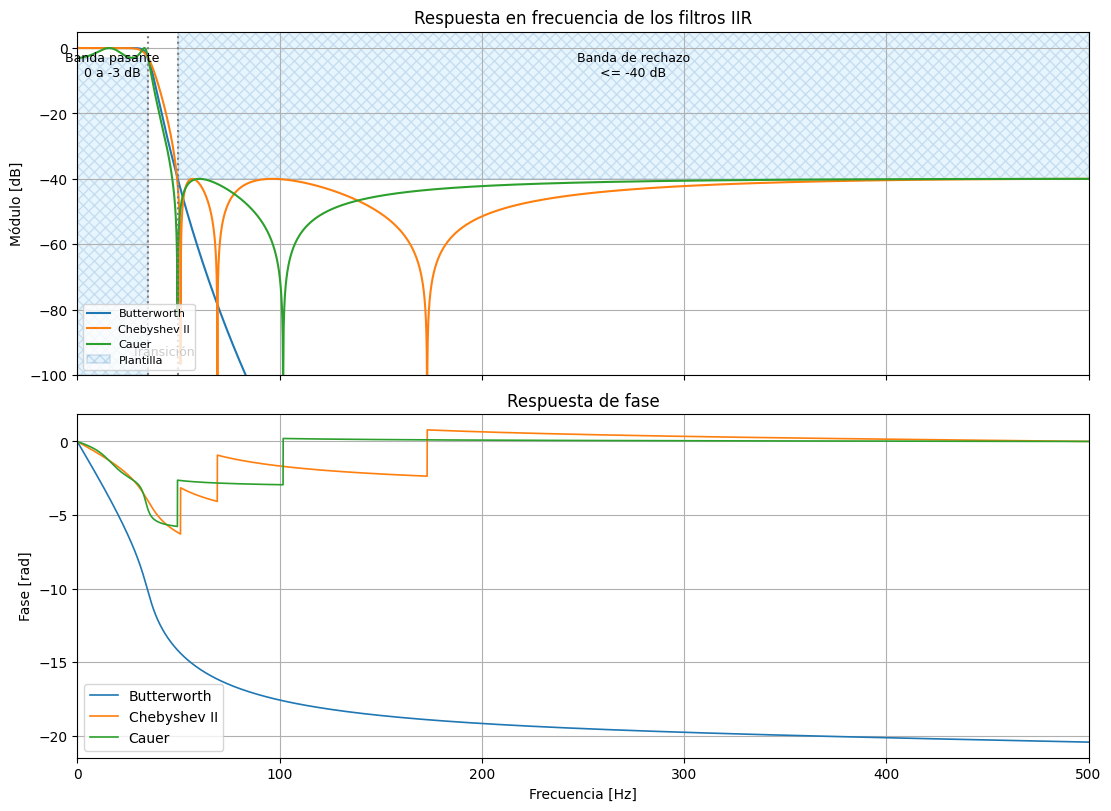

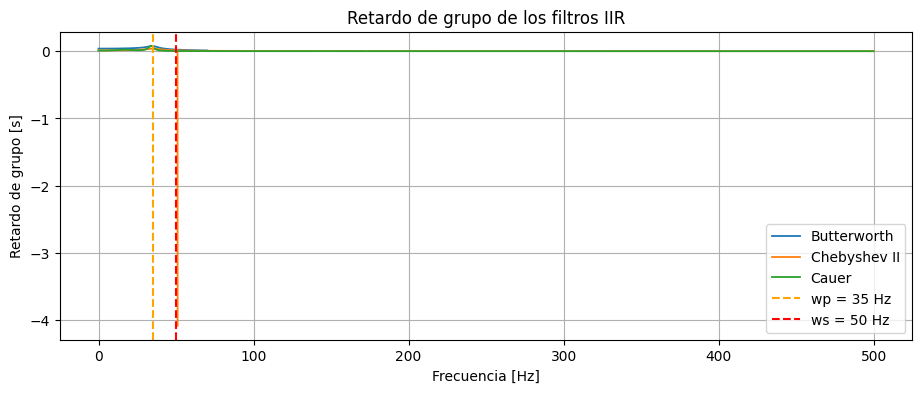

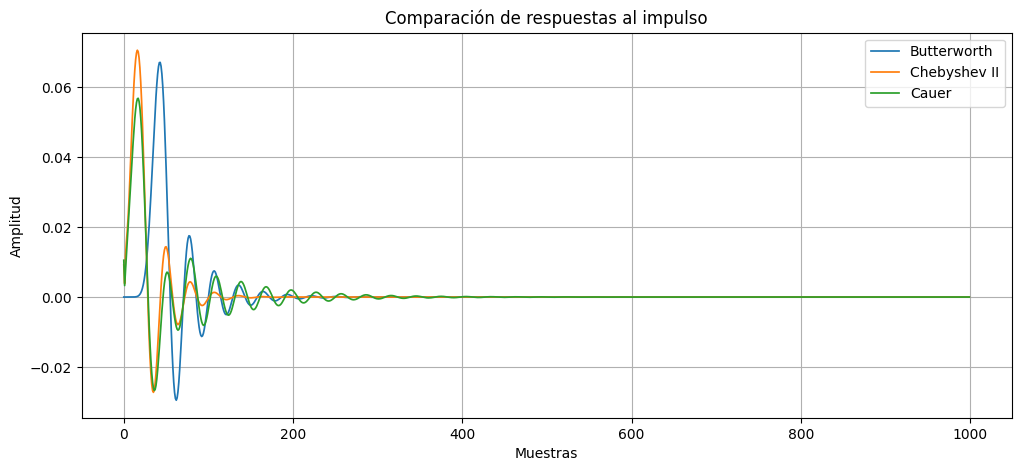

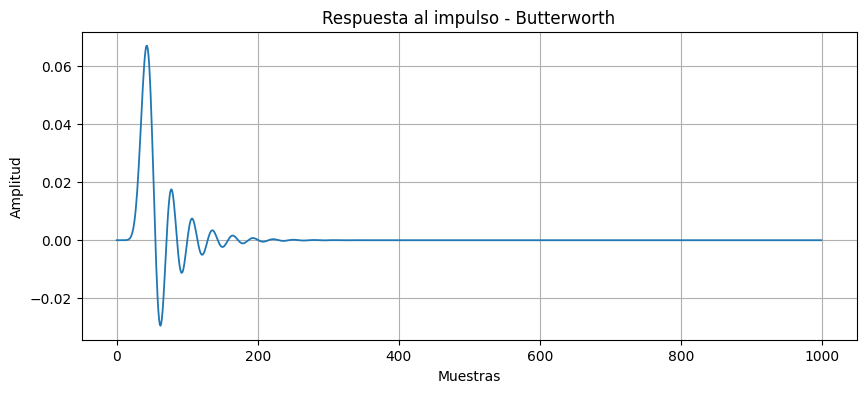

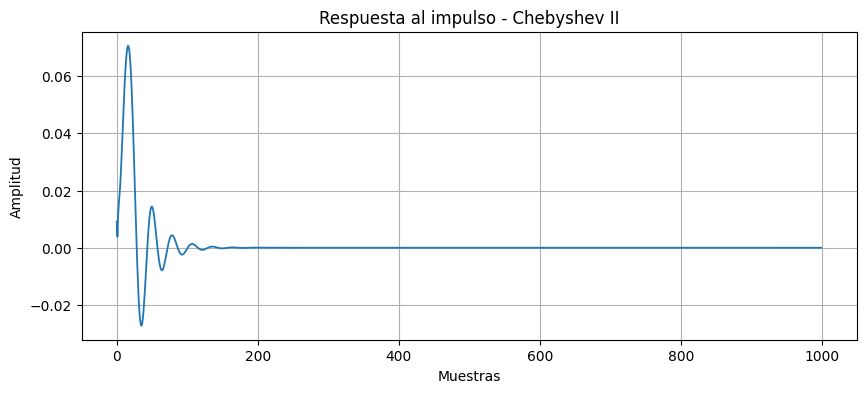

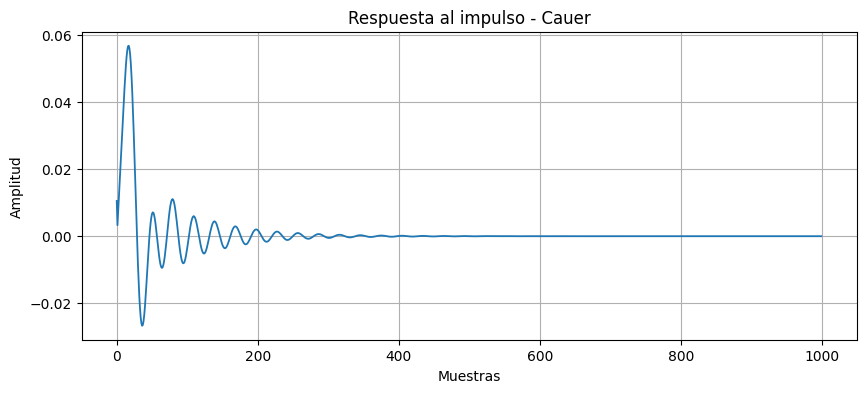

Butterworth: última muestra sobre el umbral = 195, duración estimada = 0.1950 s
Chebyshev II: última muestra sobre el umbral = 122, duración estimada = 0.1220 s
Cauer: última muestra sobre el umbral = 288, duración estimada = 0.2880 s


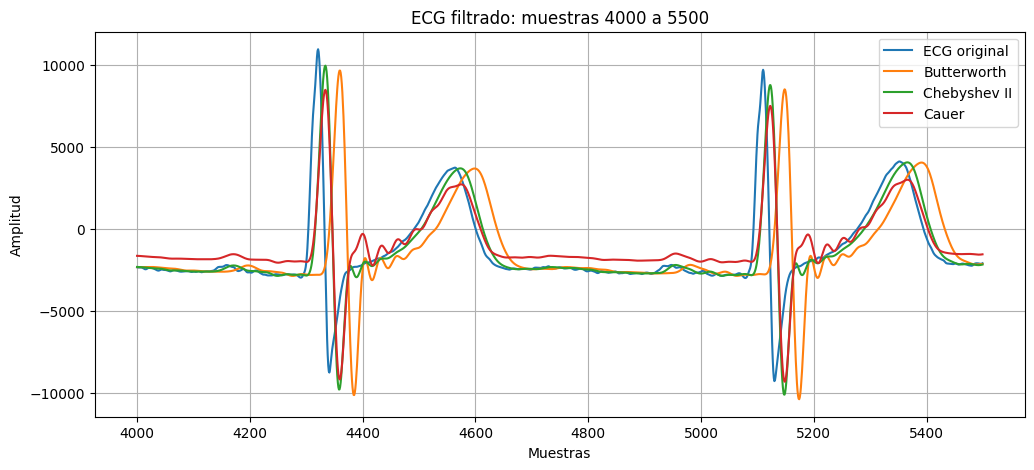

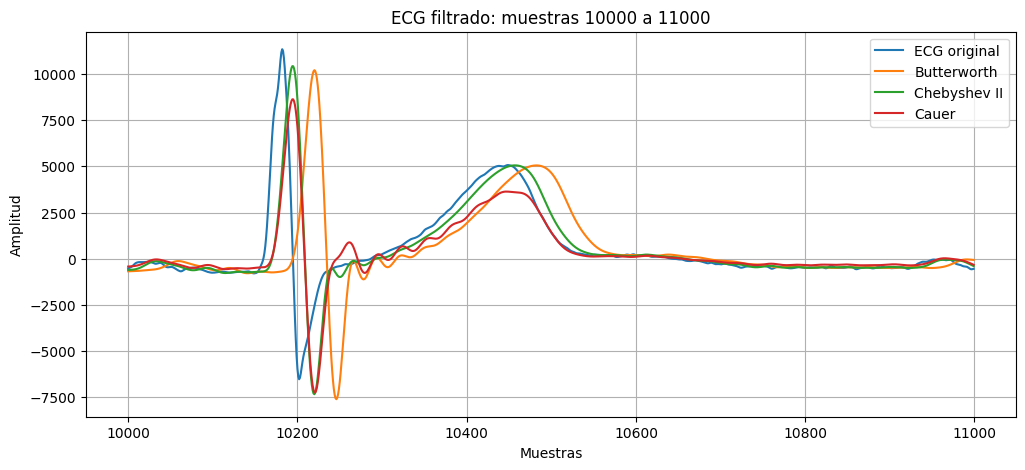

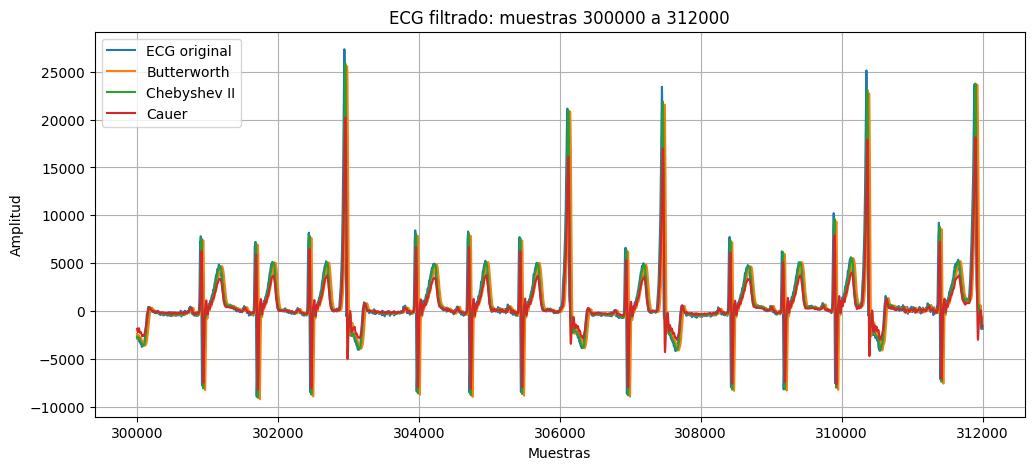

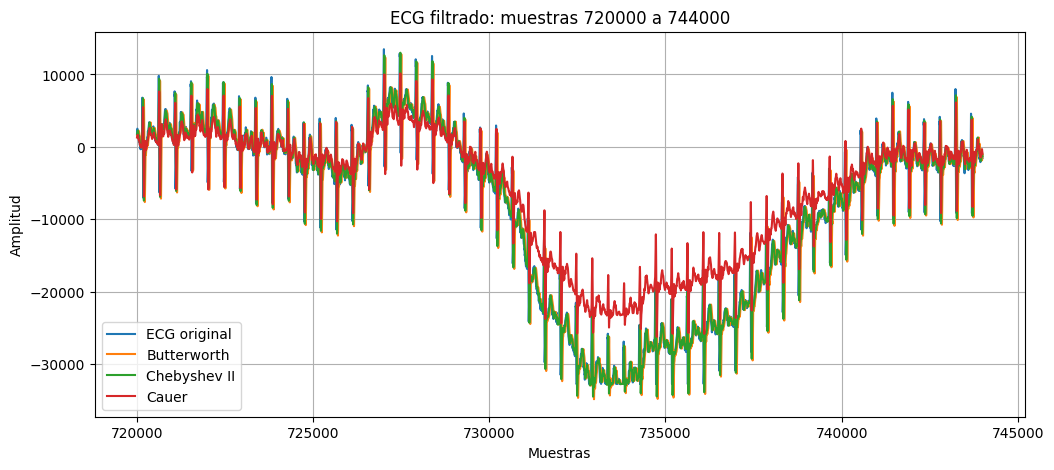

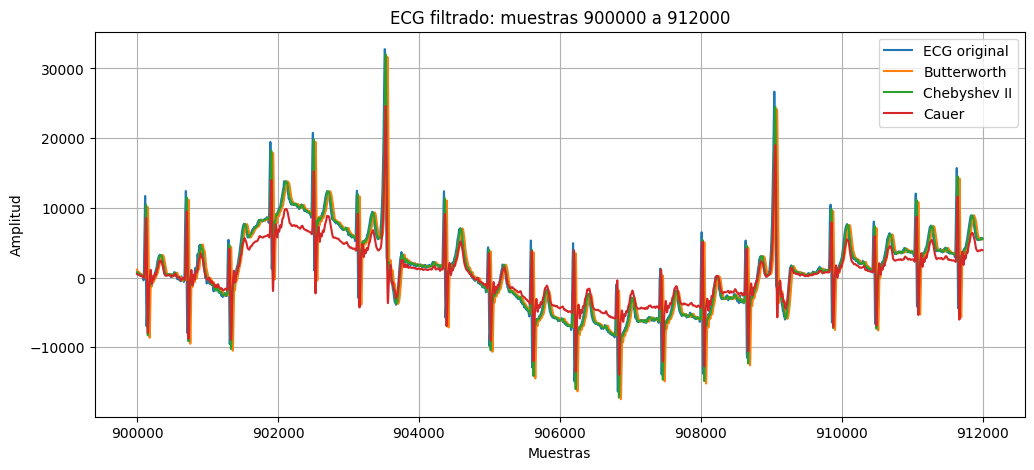

In [22]:

# ============================================================
# TS7 - FILTRADO DIGITAL LINEAL DE ECG
# FILTROS IIR: BUTTERWORTH, CHEBYSHEV II Y CAUER
# ============================================================

#%% IMPORTACIONES

import numpy as np
import scipy.io as sio
import scipy.signal as sig
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle


#%% 1. LECTURA DE LA SEÑAL ECG

fs_ecg = 1000.0  # Frecuencia de muestreo [Hz]

mat_struct = sio.loadmat('./ECG_TP4.mat')

# Extraer señal ECG
ecg_one_lead = mat_struct['ecg_lead'].flatten().astype(float)

# Patrones de latidos
hb_1 = mat_struct['heartbeat_pattern1']
hb_2 = mat_struct['heartbeat_pattern2']

# Cantidad de muestras y vector temporal
N = len(ecg_one_lead)
t_ecg = np.arange(N) / fs_ecg

print(f"Cantidad de muestras: {N}")
print(f"Duración de la señal: {N/fs_ecg:.2f} segundos")


#%% 2. DISEÑO DE LOS FILTROS IIR

wp = 35       # [Hz] Frecuencia límite de banda pasante
ws = 50       # [Hz] Frecuencia límite de banda de rechazo
Gpass = 3     # [dB] Atenuación máxima en banda pasante
Gstop = 40    # [dB] Atenuación mínima en banda de rechazo

ripple = Gpass
att = Gstop

# Diseño Butterworth
sos_butt = sig.iirdesign(
    wp, ws, Gpass, Gstop,
    ftype='butter',
    fs=fs_ecg,
    output='sos'
)

# Diseño Chebyshev tipo II
sos_cheby2 = sig.iirdesign(
    wp, ws, Gpass, Gstop,
    ftype='cheby2',
    fs=fs_ecg,
    output='sos'
)

# Diseño elíptico (Cauer)
sos_cauer = sig.iirdesign(
    wp, ws, Gpass, Gstop,
    ftype='ellip',
    fs=fs_ecg,
    output='sos'
)

# Mostrar cantidad de secciones de segundo orden
print("Secciones SOS:")
print("Butterworth:", len(sos_butt))
print("Chebyshev II:", len(sos_cheby2))
print("Cauer:", len(sos_cauer))


#%% 3. RESPUESTA EN FRECUENCIA, FASE Y RETARDO DE GRUPO

y_min, y_max = -100, 5

plt.close('all')

# Crear figuras antes de graficar
fig_resp, (ax_mod, ax_fase) = plt.subplots(
    2, 1,
    sharex=True,
    figsize=(11, 8),
    constrained_layout=True
)

fig_retardo, ax_retardo = plt.subplots(
    figsize=(11, 4)
)


def calc_resp(sos, leg_str):

    # Respuesta en frecuencia
    f, h = sig.sosfreqz(
        sos,
        worN=8192,
        fs=fs_ecg
    )

    # Módulo en dB
    modulo_db = 20 * np.log10(
        np.maximum(np.abs(h), 1e-12)
    )

    # Fase desenrollada
    fase_rad = np.unwrap(np.angle(h))

    # Frecuencia angular [rad/s]
    omega = 2 * np.pi * f

    # Retardo de grupo [s]
    retardo_s = -np.gradient(fase_rad, omega)

    # Evitar graficar retardos en regiones
    # donde el filtro rechaza prácticamente toda la señal
    umbral_db = -80

    valido = modulo_db > umbral_db

    retardo_s_plot = np.where(
        valido,
        retardo_s,
        np.nan
    )

    # Graficar módulo
    ax_mod.plot(
        f, modulo_db,
        linewidth=1.5,
        label=leg_str
    )

    # Graficar fase
    ax_fase.plot(
        f, fase_rad,
        linewidth=1.2,
        label=leg_str
    )

    # Graficar retardo de grupo
    ax_retardo.plot(
        f, retardo_s_plot,
        linewidth=1.3,
        label=leg_str
    )


# Calcular las respuestas
calc_resp(sos_butt, 'Butterworth')
calc_resp(sos_cheby2, 'Chebyshev II')
calc_resp(sos_cauer, 'Cauer')


#%% 4. GRAFICAR RESPUESTAS Y PLANTILLA

# Módulo
ax_mod.set_ylim(y_min, y_max)
ax_mod.set_xlim(0, fs_ecg/2)
ax_mod.set_ylabel("Módulo [dB]")
ax_mod.set_title("Respuesta en frecuencia de los filtros IIR")
ax_mod.grid(True)
ax_mod.legend()
#%%
# Banda pasante
rect_pasante = Rectangle(
    (0, y_min),
    wp,
    -ripple - y_min,
    facecolor="lightskyblue",
    alpha=0.20,
    edgecolor="steelblue",
    hatch="xxx",
    linewidth=1.2,
    label="Plantilla"
)

ax_mod.add_patch(rect_pasante)
 
#%% 
# Banda de rechazo
rect_rechazo = Rectangle(
    (ws, -att),
    fs_ecg/2 - ws,
    y_max + att,
    facecolor="lightskyblue",
    alpha=0.20,
    edgecolor="steelblue",
    hatch="xxx",
    linewidth=1.2
)

ax_mod.add_patch(rect_rechazo)

ax_mod.axvline(wp, color="gray", linestyle=":")
ax_mod.axvline(ws, color="gray", linestyle=":")

ax_mod.text(
    wp/2, y_max-6,
    "Banda pasante\n0 a -3 dB",
    ha="center",
    va="top",
    fontsize=9
)

ax_mod.text(
    (ws + fs_ecg/2)/2, y_max-6,
    "Banda de rechazo\n<= -40 dB",
    ha="center",
    va="top",
    fontsize=9
)

ax_mod.text(
    (wp+ws)/2, y_min+5,
    "Transición",
    ha="center",
    va="bottom",
    fontsize=9
)

ax_mod.legend(loc="lower left", fontsize=8)

# Fase
ax_fase.set_xlabel("Frecuencia [Hz]")
ax_fase.set_ylabel("Fase [rad]")
ax_fase.set_title("Respuesta de fase")
ax_fase.grid(True)
ax_fase.legend()

# Retardo de grupo
ax_retardo.axvline(
    wp, color="orange",
    linestyle="--",
    label="wp = 35 Hz"
)

ax_retardo.axvline(
    ws, color="red",
    linestyle="--",
    label="ws = 50 Hz"
)

ax_retardo.set_xlabel("Frecuencia [Hz]")
ax_retardo.set_ylabel("Retardo de grupo [s]")
ax_retardo.set_title("Retardo de grupo de los filtros IIR")
ax_retardo.grid(True)
ax_retardo.legend()

plt.show()


#%% 5. RESPUESTA AL IMPULSO

# Generar impulso unitario
delta_k = sig.unit_impulse(1000)

# Calcular respuestas impulsivas CAUSALES
resp_imp_butt = sig.sosfilt(sos_butt, delta_k)
resp_imp_cheby2 = sig.sosfilt(sos_cheby2, delta_k)
resp_imp_cauer = sig.sosfilt(sos_cauer, delta_k)


#%% 6. GRAFICAR RESPUESTAS AL IMPULSO

plt.figure(figsize=(12, 5))

plt.plot(
    resp_imp_butt,
    linewidth=1.25,
    label='Butterworth'
)

plt.plot(
    resp_imp_cheby2,
    linewidth=1.25,
    label='Chebyshev II'
)

plt.plot(
    resp_imp_cauer,
    linewidth=1.25,
    label='Cauer'
)

plt.xlabel("Muestras")
plt.ylabel("Amplitud")
plt.title("Comparación de respuestas al impulso")
plt.grid(True)
plt.legend()
plt.show()


#%% 7. RESPUESTAS AL IMPULSO INDIVIDUALES

respuestas = [
    (resp_imp_butt, 'Butterworth'),
    (resp_imp_cheby2, 'Chebyshev II'),
    (resp_imp_cauer, 'Cauer')
]

for respuesta, nombre in respuestas:

    plt.figure(figsize=(10, 4))

    plt.plot(respuesta, linewidth=1.3)

    plt.xlabel("Muestras")
    plt.ylabel("Amplitud")
    plt.title(f"Respuesta al impulso - {nombre}")
    plt.grid(True)

    plt.show()


#%% 8. ESTIMACIÓN DE DURACIÓN DE LOS TRANSITORIOS

# Se considera que el transitorio terminó cuando
# la respuesta permanece por debajo del 1% de su
# amplitud máxima durante el resto de la observación.

for respuesta, nombre in respuestas:

    umbral = 0.01 * np.max(np.abs(respuesta))

    indices = np.where(
        np.abs(respuesta) > umbral
    )[0]

    if len(indices) > 0:

        ultima_muestra = indices[-1]

        duracion_s = ultima_muestra / fs_ecg

        print(
            f"{nombre}: "
            f"última muestra sobre el umbral = {ultima_muestra}, "
            f"duración estimada = {duracion_s:.4f} s"
        )


#%% 9. FILTRADO DE LA SEÑAL ECG

# Inicia  para reducir el transitorio artificial
# producido por condiciones iniciales nulas.

zi_butt = sig.sosfilt_zi(sos_butt) * ecg_one_lead[0]
zi_cheby2 = sig.sosfilt_zi(sos_cheby2) * ecg_one_lead[0]
zi_cauer = sig.sosfilt_zi(sos_cauer) * ecg_one_lead[0]

# Filtrado causal
ECG_f_butt, _ = sig.sosfilt(
    sos_butt,
    ecg_one_lead,
    zi=zi_butt
)

ECG_f_cheby2, _ = sig.sosfilt(
    sos_cheby2,
    ecg_one_lead,
    zi=zi_cheby2
)

ECG_f_cauer, _ = sig.sosfilt(
    sos_cauer,
    ecg_one_lead,
    zi=zi_cauer
)


#%% 10. REGIONES  CON RUIDO

cant_muestras = len(ecg_one_lead)

regs_interes = (
    [4000, 5500],
    [10000, 11000]
)

for ii in regs_interes:

    inicio = int(max(0, ii[0]))
    fin = int(min(cant_muestras, ii[1]))

    if inicio >= fin:
        print(f"Región no disponible: {inicio} a {fin}")
        continue

    zoom_region = np.arange(inicio, fin)

    plt.figure(figsize=(12, 5))

    plt.plot(
        zoom_region,
        ecg_one_lead[inicio:fin],
        label='ECG original',
        linewidth=1.5
    )

    plt.plot(
        zoom_region,
        ECG_f_butt[inicio:fin],
        label='Butterworth'
    )

    plt.plot(
        zoom_region,
        ECG_f_cheby2[inicio:fin],
        label='Chebyshev II'
    )

    plt.plot(
        zoom_region,
        ECG_f_cauer[inicio:fin],
        label='Cauer'
    )

    plt.title(
        f'ECG filtrado: muestras {inicio} a {fin}'
    )

    plt.ylabel('Amplitud')
    plt.xlabel('Muestras')

    plt.legend()
    plt.grid(True)
    plt.show()


#%% 11. REGIONES  SIN RUIDO

regs_interes = (
    np.array([5, 5.2]) * 60 * fs_ecg,
    np.array([12, 12.4]) * 60 * fs_ecg,
    np.array([15, 15.2]) * 60 * fs_ecg
)

for ii in regs_interes:

    inicio = int(max(0, ii[0]))
    fin = int(min(cant_muestras, ii[1]))

    if inicio >= fin:
        print(f"Región no disponible: {inicio} a {fin}")
        continue

    zoom_region = np.arange(inicio, fin)

    plt.figure(figsize=(12, 5))

    plt.plot(
        zoom_region,
        ecg_one_lead[inicio:fin],
        label='ECG original',
        linewidth=1.5
    )

    plt.plot(
        zoom_region,
        ECG_f_butt[inicio:fin],
        label='Butterworth'
    )

    plt.plot(
        zoom_region,
        ECG_f_cheby2[inicio:fin],
        label='Chebyshev II'
    )

    plt.plot(
        zoom_region,
        ECG_f_cauer[inicio:fin],
        label='Cauer'
    )

    plt.title(
        f'ECG filtrado: muestras {inicio} a {fin}'
    )

    plt.ylabel('Amplitud')
    plt.xlabel('Muestras')

    plt.legend()
    plt.grid(True)
    plt.show()


### Análisis de las respuestas al impulso y de fase

Las respuestas al impulso de los tres filtros presentan oscilaciones amortiguadas que tienden a cero, evidenciando un comportamiento estable. Butterworth presenta un pico inicial desplazado y oscilaciones de mayor amplitud en algunas muestras, mientras que Chebyshev II y Cauer muestran respuestas temporales similares, aunque con diferencias en sus amplitudes.

En cuanto a la respuesta de fase, los tres filtros presentan un comportamiento no lineal. Butterworth muestra una variación continua, mientras que Chebyshev II y Cauer presentan saltos. Estas diferencias implican distintos retardos para las componentes frecuenciales de la señal, lo que puede modificar la morfología temporal del ECG.